# Unemployment Analysis with Python

## CodeAlpha Internship - Task 2

### Objective
Analyze unemployment rate data using Python to identify:
- Unemployment trends
- Regional differences
- Monthly patterns
- COVID-19 impact
- Urban and rural differences
- Insights relevant to economic and social policies

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [5]:
df = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [6]:
print("Rows and Columns:", df.shape)

Rows and Columns: (267, 9)


In [7]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Region.1', 'longitude', 'latitude'],
      dtype='str')


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    str    
 1    Date                                     267 non-null    str    
 2    Frequency                                267 non-null    str    
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                  267 non-null    str    
 7   longitude                                 267 non-null    float64
 8   latitude                                  267 non-null    float64
dtypes: float64(4), int64(1), str(4)
memory usage: 26.0 KB


In [9]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),longitude,latitude
count,267.000000,2.670000e+02,267.000000,267.000000,267.000000
mean,12.236929,1.396211e+07,41.681573,22.826048,80.532425
std,10.803283,1.336632e+07,7.845419,6.270731,5.831738
min,0.500000,1.175420e+05,16.770000,10.850500,71.192400
25%,4.845000,2.838930e+06,37.265000,18.112400,76.085600
50%,9.650000,9.732417e+06,40.390000,23.610200,79.019300
75%,16.755000,2.187869e+07,44.055000,27.278400,85.279900
max,75.850000,5.943376e+07,69.690000,33.778200,92.937600


In [10]:
df.columns = df.columns.str.strip()

print(df.columns)

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Region.1', 'longitude', 'latitude'],
      dtype='str')


In [11]:
df.isnull().sum()

Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64

In [12]:
df = df.dropna()

In [13]:
df.isnull().sum()

Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64

In [15]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0
Duplicate rows: 0


In [17]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
print(df['Date'].head())
print(df['Date'].dtype)

0   2020-01-31
1   2020-02-29
2   2020-03-31
3   2020-04-30
4   2020-05-31
Name: Date, dtype: datetime64[us]
datetime64[us]


In [19]:
#avg
average_rate = df['Estimated Unemployment Rate (%)'].mean()

print("Average Unemployment Rate:", round(average_rate, 2), "%")


Average Unemployment Rate: 12.24 %


In [20]:
#high

highest_rate = df['Estimated Unemployment Rate (%)'].max()

print("Highest Unemployment Rate:", round(highest_rate, 2), "%")

Highest Unemployment Rate: 75.85 %


In [22]:
#low

lowest_rate = df['Estimated Unemployment Rate (%)'].min()

print("Lowest Unemployment Rate:", round(lowest_rate, 2), "%")

Lowest Unemployment Rate: 0.5 %


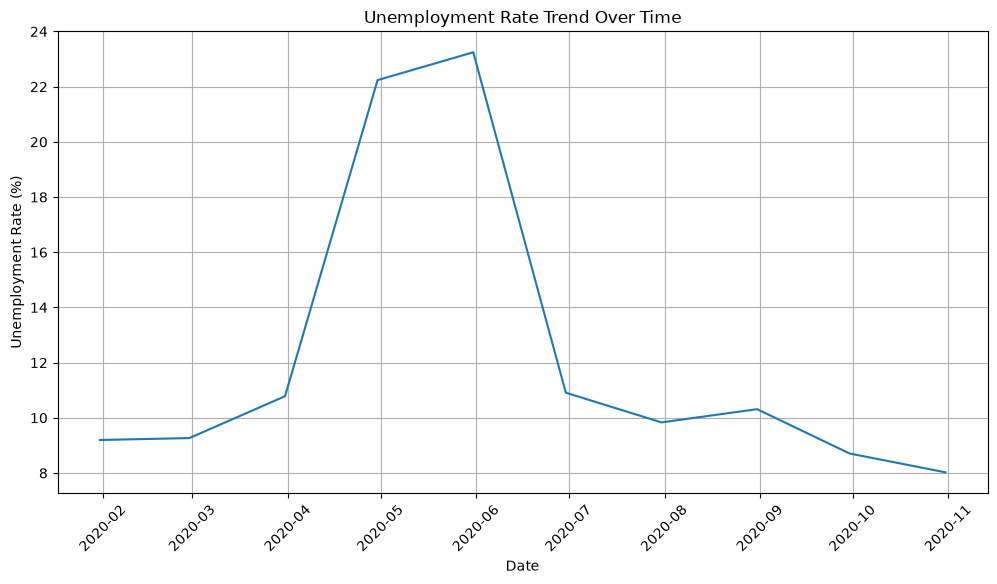

In [24]:
daily_rate = (
    df.groupby('Date')['Estimated Unemployment Rate (%)']
    .mean()
)
plt.figure(figsize=(12, 6))

plt.plot(
    daily_rate.index,
    daily_rate.values
)

plt.title("Unemployment Rate Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [26]:
df['COVID_Period'] = np.where(
    df['Date'] < '2020-03-01',
    'Before COVID',
    'During COVID'
)
df[['Date', 'COVID_Period']].head()
covid_analysis = (
    df.groupby('COVID_Period')['Estimated Unemployment Rate (%)']
    .mean()
)

print(covid_analysis)

COVID_Period
Before COVID     9.231346
During COVID    12.963860
Name: Estimated Unemployment Rate (%), dtype: float64


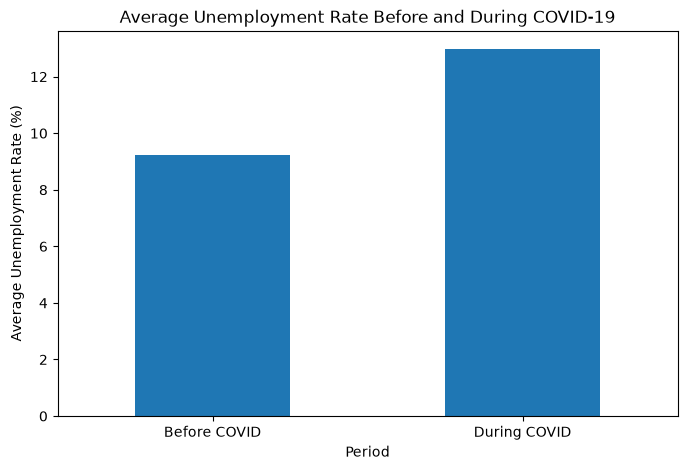

In [27]:
plt.figure(figsize=(8, 5))

covid_analysis.plot(kind='bar')

plt.title("Average Unemployment Rate Before and During COVID-19")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)

plt.show()

Month
1      9.196538
2      9.266154
3     10.782593
4     22.236154
5     23.244444
6     10.911111
7      9.834444
8     10.313333
9      8.705926
10     8.026296
Name: Estimated Unemployment Rate (%), dtype: float64


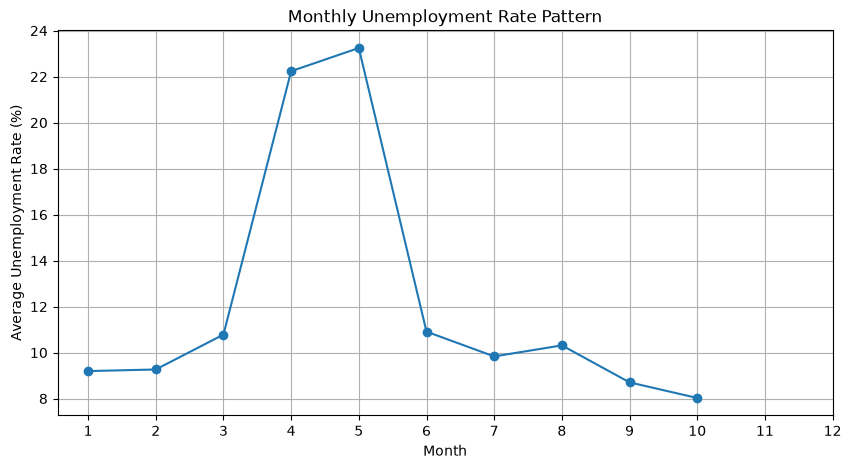

In [28]:
df['Month'] = df['Date'].dt.month
monthly_rate = (
    df.groupby('Month')['Estimated Unemployment Rate (%)']
    .mean()
)

print(monthly_rate)
plt.figure(figsize=(10, 5))

monthly_rate.plot(kind='line', marker='o')

plt.title("Monthly Unemployment Rate Pattern")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(range(1, 13))

plt.grid(True)

plt.show()

Region
Haryana             27.477000
Tripura             25.055000
Jharkhand           19.539000
Bihar               19.471000
Delhi               18.414000
Puducherry          17.942000
Jammu & Kashmir     16.477778
Himachal Pradesh    16.065000
Rajasthan           15.868000
Tamil Nadu          12.187000
Goa                 12.167000
Punjab              11.981000
Uttarakhand         11.156000
West Bengal         10.192000
Sikkim               9.792500
Uttar Pradesh        9.737000
Kerala               9.434000
Andhra Pradesh       8.664000
Maharashtra          7.979000
Chhattisgarh         7.819000
Karnataka            7.668000
Madhya Pradesh       6.854000
Telangana            6.833000
Odisha               6.462000
Gujarat              6.376000
Assam                4.856000
Meghalaya            3.866000
Name: Estimated Unemployment Rate (%), dtype: float64


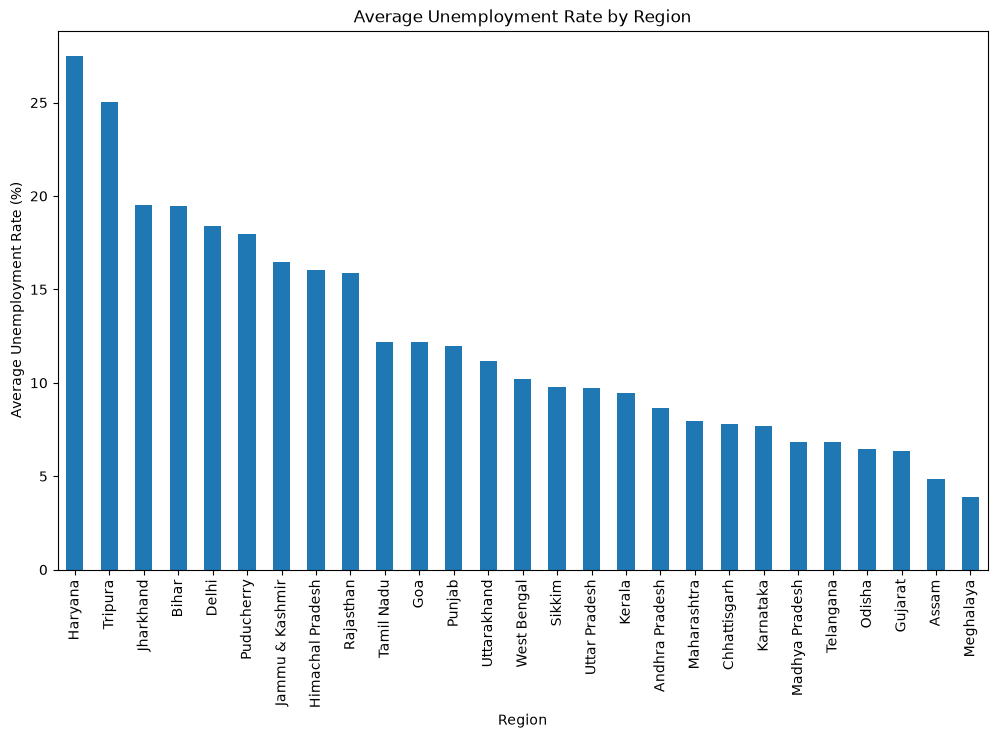

In [29]:
region_rate = (
    df.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

print(region_rate)
plt.figure(figsize=(12, 7))

region_rate.plot(kind='bar')

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)

plt.show()

                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                  1.00000   
Estimated Labour Participation Rate (%)                         -0.07354   

                                         Estimated Labour Participation Rate (%)  
Estimated Unemployment Rate (%)                                         -0.07354  
Estimated Labour Participation Rate (%)                                  1.00000  


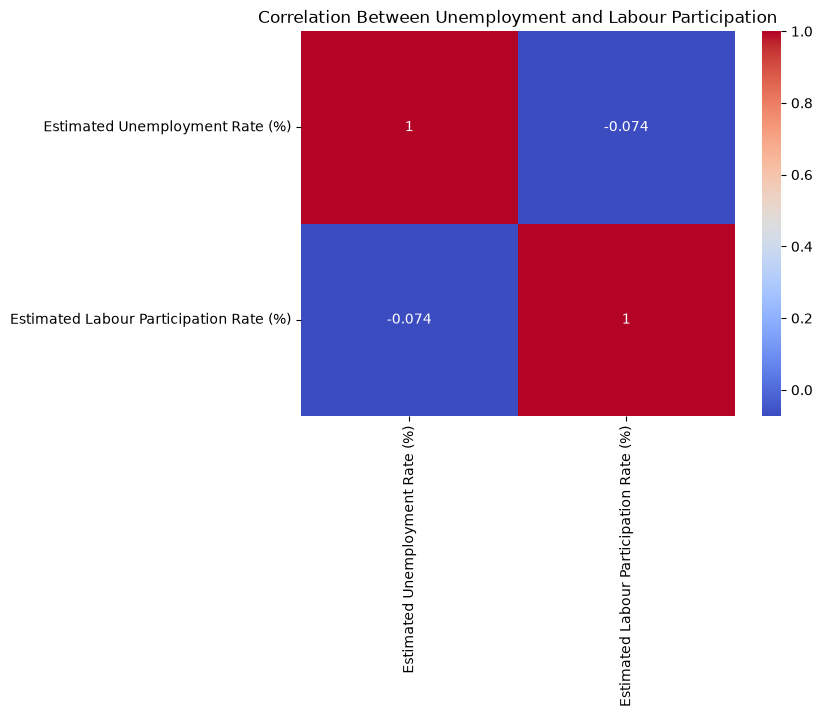

In [31]:
correlation = df[
    [
        'Estimated Unemployment Rate (%)',
        'Estimated Labour Participation Rate (%)'
    ]
].corr()

print(correlation)
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Between Unemployment and Labour Participation")

plt.show()

# Economic and Social Policy Insights

The analysis can provide useful information for policymakers:

- Employment-support programs can be considered during major economic
  disruptions.

- Regions with relatively higher unemployment may require targeted
  employment-generation programs.

- Skill-development and training programs can help improve employment
  opportunities.

- Differences between urban and rural unemployment can help policymakers
  design location-specific employment policies.

- Monitoring unemployment trends can help identify periods that may require
  additional economic support.